# 09 — Covariance robustness and serial-dependence sensitivity

Keep notebook 08's **paper-style FX mean equations**, audited instruments, and **321 frozen months**
for both USD and EUR investors. Recheck full diagonal dynamics under these corrected means, then
allow a second shock lag in grouped BEKK. Report all four covariance specifications and all fixed
HAC bandwidths; do not choose a model or bandwidth by its currency-risk p-value.

Run notebook 08 first, then **Run All** in the existing Miniconda **base** kernel. There are no downloads.
The likelihood extension is in [covariance_robustness.py](covariance_robustness.py); notebook 08's
[pricing_robustness.py](pricing_robustness.py), source data and earlier outputs remain unchanged.

In [1]:
SNAPSHOT="data/fixed_2026-11-13/from_2000-01"
UPSTREAM="output/08_specification_audit/fixed_2026-11-13/2000-01_2026-09/spec_d7a542e8"
MODELS=["scalar11","grouped11","diagonal11","grouped21"]
HAC_LAGS=[0,3,6,12]
TEST_LAGS=12
MAX_ITER=2200
SE_STEP_TOL=.01
REUSE_FITS=True
MODEL_VERSION="covariance_score_hac_v1"

from pathlib import Path
from io import BytesIO
import hashlib,importlib,importlib.metadata,json,os,platform,sys
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from packaging.version import Version
if Version(importlib.metadata.version("statsmodels"))<Version("0.15.0"):
    raise RuntimeError("Update statsmodels to 0.15.0 and restart the same base kernel.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__!=importlib.metadata.version("statsmodels"):
    raise RuntimeError("Restart the same kernel to discard old statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display,Markdown
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pricing_robustness as base
import covariance_robustness as model
importlib.reload(base);importlib.reload(model)
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
engine_hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ["pricing_robustness.py","covariance_robustness.py"]}
print("Python:",sys.executable);print("Packages:",versions)
if not MODELS or len(set(MODELS))!=len(MODELS) or any(m not in model.MODELS for m in MODELS):raise ValueError("Invalid covariance models.")
if not HAC_LAGS or len(set(HAC_LAGS))!=len(HAC_LAGS) or 0 not in HAC_LAGS or any(type(h)!=int or h<0 for h in HAC_LAGS):raise ValueError("Include lag zero and distinct nonnegative integer HAC lags.")
pd.set_option("display.max_columns",18);pd.set_option("display.max_rows",50)
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.16})
source,upstream=ROOT/SNAPSHOT,ROOT/UPSTREAM
manifest=json.loads((source/"manifest.json").read_text());raw=(source/"dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset checksum differs.")
data=pd.read_csv(BytesIO(raw),index_col=0,float_precision="round_trip")
data.index=pd.PeriodIndex(data.index,freq="M",name="month")
if not data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")):raise ValueError("Discontinuous model months.")
if max(HAC_LAGS)>=len(data):raise ValueError("HAC lag exceeds sample length.")
upstream_hashes={}
def upstream_bytes(name):
    content=(upstream/name).read_bytes();upstream_hashes[name]=hashlib.sha256(content).hexdigest();return content
prior=json.loads(upstream_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["main_first"]!=str(data.index[0]) or
    prior["main_last"]!=str(data.index[-1]) or prior["main_observations"]!=len(data) or prior["engine_sha256"]!=engine_hashes["pricing_robustness.py"]):
    raise ValueError("Notebook 08 provenance/model differs.")
old_summary=pd.read_csv(BytesIO(upstream_bytes("all_fit_summary.csv")),index_col=0,float_precision="round_trip")
conditioning_root=ROOT/prior["upstream"]
samples,designs,references={}, {}, {}
for currency in ["USD","EUR"]:
    designs[currency]={}
    for label in ["W","H","O"]:
        name=f"conditioning_{currency.lower()}_{label}.csv";content=(conditioning_root/name).read_bytes()
        if hashlib.sha256(content).hexdigest()!=prior["upstream_file_sha256"][name]:raise ValueError("Conditioning design checksum differs.")
        z=pd.read_csv(BytesIO(content),index_col=0,float_precision="round_trip")
        if not pd.PeriodIndex(z.index,freq="M").equals(data.index):raise ValueError("Conditioning months differ.")
        design=z.to_numpy()
        if not np.isfinite(design).all() or np.linalg.matrix_rank(design)!=design.shape[1]:raise ValueError("Invalid price design.")
        designs[currency][label]=design
    equity=data[[f"rx_{a}_{currency.lower()}" for a in ["world","us","hu"]]].to_numpy()*100
    fx=np.c_[data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    samples[currency]=np.c_[equity,fx]
    for name in ["scalar11","grouped11"]:
        key=f"{currency}_paper_{model.MODELS[name][0]}_full"
        with np.load(BytesIO(upstream_bytes(f"parameters_{key}.npz")),allow_pickle=False) as arrays:
            references[(currency,name)]={k:arrays[k].copy() for k in arrays.files}
OUT=ROOT/"output"/"09_covariance_robustness"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/"paper_fx_means"
OUT.mkdir(parents=True,exist_ok=True)
display(pd.DataFrame({"first":[str(data.index[0])],"last":[str(data.index[-1])],"months":[len(data)],"mean_equations":["paper-style: all five series"]}))

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,months,mean_equations
0,2000-01,2026-09,321,paper-style: all five series


## 1. Fix the covariance comparison

Write the symmetric diagonal BEKK recursion explicitly (the label `21` means **two shock lags,
 one covariance lag** here):

$$\boxed{H_t=CC'+\sum_{\ell=1}^{p}A_\ell\varepsilon_{t-\ell}\varepsilon_{t-\ell}'A_\ell'+BH_{t-1}B',\quad p\in\{1,2\}.}$$

| Model | Shock lags | Dynamics shared by | Parameters |
|---|---:|---|---:|
| `scalar11` | 1 | All five series | 34 |
| `grouped11` | 1 | World/US; Hungary; two FX series | 38 |
| `diagonal11` | 1 | Separate for every series | 42 |
| `grouped21` | 2 | Same three groups as `grouped11` | 41 |

The first two are verified notebook 08 reference estimates. Unlike the retired notebook 07 diagonal
fit, the new diagonal fit imposes the paper-style FX means. All models retain the free $CC'$ intercept,
time-varying world/FX prices and constant local equity prices. This remains a covariance sensitivity
exercise rather than an exact replication of the paper's variance-targeting specification.

For each group use positive softmax weights with $\sum_\ell\alpha_{\ell,i}+\beta_i<1$,
$A_{\ell,ii}=\sqrt{\alpha_{\ell,i}}$, $B_{ii}=\sqrt{\beta_i}$. Initialize

$$\Sigma_{ij}=\frac{(CC')_{ij}}{1-\sum_\ell\sqrt{\alpha_{\ell,i}\alpha_{\ell,j}}-\sqrt{\beta_i\beta_j}}.$$

Set $H_0=\Sigma$ and unavailable pre-sample innovation outer products to $\Sigma$; differentiate this
initialization too. This construction preserves positive definiteness and contraction of the covariance
recursion. It does not prove strict stationarity of the observed instrument-dependent mean system.
Higher-order BEKK is described by [Engle & Kroner (1995)](https://doi.org/10.1017/S0266466600009063).
The one-lag restriction lies on the boundary of the two-lag parameterization: use descriptive AIC/BIC,
not an ordinary LR chi-square test. Use the same sample in every comparison.

In [2]:
def make_case(currency,name):
    y=samples[currency]
    return {"id":f"{currency}_{name}","currency":currency,"name":name,"y":y,"pdesign":designs[currency],"scales":y.std(axis=0,ddof=1)}
def args(case):return (case["y"],case["pdesign"],case["scales"],case["name"])
checks=[]
for currency in ["USD","EUR"]:
    for name in ["scalar11","grouped11"]:
        c=make_case(currency,name);saved=references[(currency,name)];f=model.filter_model(saved["theta"],*args(c))
        for new,old in [("H","H"),("mu","mu"),("errors","residuals")]:np.testing.assert_allclose(f[new],saved[old],atol=1e-9,rtol=1e-11)
        old=old_summary.loc[f"{currency}_paper_{model.MODELS[name][0]}_full"]
        np.testing.assert_allclose(-f["losses"].sum(),old["loglik"],atol=1e-8,rtol=0)
        if np.max(np.abs(f["scores"].mean(axis=0)))>=1e-4:raise ValueError("Reference gradient is no longer small.")
    for name in ["diagonal11","grouped21"]:
        c=make_case(currency,name);theta=model.initial_theta(*args(c))
        theta[-model.layout(c["pdesign"],name)[1]:]+=np.linspace(-.15,.15,model.layout(c["pdesign"],name)[1])
        for idx in base.price_indices(c["pdesign"]).values():theta[idx[1:]]=np.linspace(.1,-.08,len(idx)-1)
        sub=(c["y"][:35],{a:z[:35] for a,z in c["pdesign"].items()},c["scales"],name)
        analytic=model.objective(theta,*sub)[1];numeric=base.numerical_gradient(lambda t:model.objective(t,*sub)[0],theta)
        np.testing.assert_allclose(analytic,numeric,atol=5e-6,rtol=5e-5)
        checks.append({"perspective":currency,"model":name,"maximum_gradient_error":np.max(np.abs(analytic-numeric))})
    c=make_case(currency,"grouped21");parent=references[(currency,"grouped11")]["theta"]
    expanded=model.expand_grouped(parent,"grouped21");weights=parent[-6:].reshape(3,2)
    expanded[-9:]=np.c_[weights[:,0],np.full(3,-35.),weights[:,1]].ravel()
    np.testing.assert_allclose(model.filter_model(expanded,*args(c))["H"],references[(currency,"grouped11")]["H"],atol=1e-9,rtol=1e-11)
    c=make_case(currency,"diagonal11")
    np.testing.assert_allclose(model.filter_model(model.expand_grouped(parent,"diagonal11"),*args(c))["H"],references[(currency,"grouped11")]["H"],atol=1e-10,rtol=1e-11)
display(pd.DataFrame(checks))

,perspective,model,maximum_gradient_error
0,USD,diagonal11,1.067806e-08
1,USD,grouped21,1.267846e-08
2,EUR,diagonal11,1.838205e-08
3,EUR,grouped21,2.115487e-08


## 2. Fit the four planned specifications

For each extension use a warm start from grouped BEKK and an independent moment-based start.
Each start uses BFGS exploration followed by bounded L-BFGS-B polishing. Accept optimizer success
only with a small raw likelihood gradient, and fail if a lower unconverged candidate remains.
A fit on a bound remains an audit result; its usual uncertainty/tests will be withheld.

Caches include the input arrays, both engine hashes, package versions and optimizer settings.
Every reused estimate is re-filtered and checked. Set `REUSE_FITS=False` for a full re-estimation.

In [3]:
fits,start_rows={},[]
for currency in ["USD","EUR"]:
    for name in MODELS:
        case=make_case(currency,name);key=case["id"];print(key,flush=True)
        if name in ["scalar11","grouped11"]:
            theta=references[(currency,name)]["theta"]
            case.update(theta=theta,filter=model.filter_model(theta,*args(case)),origin="verified notebook 08")
            fits[key]=case;print("  verified upstream reference",flush=True);continue
        config={"version":MODEL_VERSION,"engines":engine_hashes,"source_sha256":manifest["exports"]["dataset.csv"],
            "case":key,"first":str(data.index[0]),"last":str(data.index[-1]),"n":len(data),"packages":versions,
            "python":platform.python_version(),"max_iter":MAX_ITER,"warm_lag2_share":.2,"independent_start":[.1,.75,.5],
            "upstream_sha256":upstream_hashes}
        payload=json.dumps(config,sort_keys=True).encode()+case["y"].tobytes()+b"".join(case["pdesign"][a].tobytes() for a in ["W","H","O"])
        fingerprint=hashlib.sha256(payload).hexdigest();path=OUT/f"fit_{key}.json"
        cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        limits=model.bounds(case["pdesign"],name);candidate=np.asarray(cached["theta"]) if cached else np.array([])
        record=None
        if candidate.shape==(len(limits),) and cached.get("fingerprint")==fingerprint and np.isfinite(candidate).all() and (candidate>=limits[:,0]).all() and (candidate<=limits[:,1]).all():
            value,gradient=model.objective(candidate,*args(case))
            if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:record=cached;print("  verified cached fit",flush=True)
        parent=references[(currency,"grouped11")]["theta"]
        starts=[model.expand_grouped(parent,name),model.initial_theta(*args(case))]
        if record is None:
            best,runs=model.fit_starts(args(case),starts,maxiter=MAX_ITER)
            record={"fingerprint":fingerprint,"configuration":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs}
            path.write_text(json.dumps(record,indent=2)+"\n")
        for row in record["starts"]:start_rows.append({"case":key,**row})
        theta=np.asarray(record["theta"]);case.update(theta=theta,filter=model.filter_model(theta,*args(case)),origin="new covariance sensitivity")
        fits[key]=case
starting_points=pd.DataFrame(start_rows)
display(starting_points)

USD_scalar11


  verified upstream reference


USD_grouped11


  verified upstream reference


USD_diagonal11


  verified cached fit


... (7 outputs left out)

  verified cached fit


EUR_grouped21


  verified cached fit


,case,start,success,mean_nll,max_abs_gradient,iterations,message
0,USD_diagonal11,1,True,11.568179,3.983298e-06,321,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
1,USD_diagonal11,2,True,11.568179,4.085694e-06,343,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
2,USD_grouped21,1,True,11.561848,3.756532e-06,294,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
3,USD_grouped21,2,True,11.561848,2.297225e-06,331,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
4,EUR_diagonal11,1,True,11.560787,5.390447e-06,216,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
5,EUR_diagonal11,2,True,11.560787,6.023865e-07,413,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
6,EUR_grouped21,1,True,11.553013,3.809063e-06,217,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
7,EUR_grouped21,2,True,11.553013,3.462234e-06,348,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## 3. Check uncertainty and residual dependence

Let $g_t(\theta)$ be the full joint negative-log-likelihood score and $A$ its average Hessian. Use
centered scores $\tilde g_t=g_t-\bar g$ and the Bartlett score covariance

$$S_L=\frac1T\left[\sum_t\tilde g_t\tilde g_t'+\sum_{\ell=1}^{L}\left(1-\frac{\ell}{L+1}\right)
\sum_{t=\ell+1}^{T}(\tilde g_t\tilde g_{t-\ell}'+\tilde g_{t-\ell}\tilde g_t')\right],\quad
\widehat V_L=A^{-1}S_LA^{-1}/T.$$

Report $L=0,3,6,12$ months with no finite-sample multiplier. $L=0$ must reproduce notebook 08's
sandwich covariance. The Bartlett convention matches the official
[statsmodels implementation](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.weights_bartlett.html).
HAC allows serial score dependence under suitable weak-dependence/regularity conditions; it
**does not repair a misspecified mean or covariance, prove identification, or turn coefficients into
structural risk prices**. Interpret rejected-model estimates as conditional sensitivity results.
HAC SEs can increase or decrease as score autocovariances enter; a smaller p-value is not evidence
that the covariance specification is correct.

Withhold all ordinary tests at parameter bounds, nonpositive/ill-conditioned curvature, or unstable
numerical differentiation. Check robust price SEs at two Hessian steps separately for each bandwidth.
The price constancy test jointly sets the **nine FX slopes** to zero; zero FX pricing sets **eleven
FX coefficients** to zero. Neither test says that the mean HUF price alone differs from zero.

For diagnostics, retain the 12-month Ljung–Box/ARCH screens from notebook 08 and add Holm-adjusted
p-values within each model's five mean tests, five squared-residual tests, five ARCH tests, and ten
whitened cross-product tests. These screens remain approximate after estimated GARCH parameters;
Holm does not calibrate the individual tests. Keep nominal flags visible too. Do not compare flag
counts as a formal model-selection test.

In [4]:
from statsmodels.stats.multitest import multipletests
summary_rows,test_rows,coef_rows,residual_rows,cross_rows,score_rows=[],[],[],[],[],[]
for key,case in fits.items():
    theta,f=case["theta"],case["filter"]
    inf=model.inference(theta,args(case),f,hac_lags=HAC_LAGS,se_step_tol=SE_STEP_TOL);case["inference"]=inf
    labels=["World","US equity","Hungary equity","HUF FX",("EUR FX" if case["currency"]=="USD" else "USD FX")]
    marginal,cross=base.diagnostics(f,labels,TEST_LAGS)
    for column in ["LB_z_p","LB_z_squared_p","ARCH_LM_p"]:
        marginal[column.replace("_p","_holm_p")]=multipletests(marginal[column],method="holm")[1]
    cross["LB_product_holm_p"]=multipletests(cross["LB_product_p"],method="holm")[1]
    residual_rows.extend({"case":key,"series":label,**row.to_dict()} for label,row in marginal.iterrows())
    cross_rows.extend({"case":key,"pair":label,**row.to_dict()} for label,row in cross.iterrows())
    k,dynamics=model.layout(case["pdesign"],case["name"]);indices=base.price_indices(case["pdesign"])
    score_z=f["scores"][:,:k]
    for i in range(k):score_rows.append({"case":key,"price_position":i,"LB_score_p":acorr_ljungbox(score_z[:,i],lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0]})
    LL=-f["losses"].sum();q=len(theta)
    j=int(np.argmin(inf["distance_to_bounds"]));bound_label=""
    if inf["near_bound"]:
        if k<=j<k+15:
            ii,jj=list(zip(*base.TRI))[j-k]
            bound_label=f"normalised C[{ii+1},{jj+1}]"+(" log diagonal" if ii==jj else "")
        else:bound_label=f"parameter position {j}"
    summary_rows.append({"case":key,"perspective":case["currency"],"model":case["name"],"n":len(data),"parameters":q,
        "loglik":LL,"AIC":-2*LL+2*q,"BIC":-2*LL+np.log(len(data))*q,"gradient":np.max(np.abs(f["scores"].mean(axis=0))),
        "Hessian_condition":inf["Hessian_condition"],"near_bound":inf["near_bound"],"closest_bound_distance":inf["distance_to_bounds"].min(),"bound_parameter":bound_label,
        "sandwich_ready_all_lags":all(v["ready"] for v in inf["estimates"].values()),
        "mean_flags":int((marginal["LB_z_p"]<.05).sum()),"variance_flags":int(((marginal["LB_z_squared_p"]<.05)|(marginal["ARCH_LM_p"]<.05)).sum()),
        "cross_flags":int((cross["LB_product_p"]<.05).sum()),
        "variance_flags_holm":int(((marginal["LB_z_squared_holm_p"]<.05)|(marginal["ARCH_LM_holm_p"]<.05)).sum()),
        "cross_flags_holm":int((cross["LB_product_holm_p"]<.05).sum()),"origin":case["origin"]})
    if case["name"] in ["scalar11","grouped11"] and inf["estimates"][0]["ready"]:
        np.testing.assert_allclose(inf["estimates"][0]["covariance"],references[(case["currency"],case["name"])]["robust_covariance"],atol=1e-7,rtol=1e-7)
    tests={"FX prices constant":np.r_[indices["H"][1:],indices["O"][1:]],"FX prices zero":np.r_[indices["H"],indices["O"]],"Local prices zero":np.array([1,2])}
    for lag,estimate in inf["estimates"].items():
        V=estimate["covariance"]
        for label,idx in tests.items():test_rows.append({"case":key,"HAC_lags":lag,"test":label,**base.wald(theta,V,idx),"inference_ready":estimate["ready"],"reason":estimate["reason"],"SE_step_difference":estimate["price_SE_step_difference"]})
        for label,idx in indices.items():
            for position,j in enumerate(idx):coef_rows.append({"case":key,"HAC_lags":lag,"price":label,"position":position,
                "estimate":base.PRICE_SCALE*theta[j],"robust_se":base.PRICE_SCALE*np.sqrt(V[j,j])})
summary=pd.DataFrame(summary_rows).set_index("case")
summary["AIC_from_best"]=summary["AIC"]-summary.groupby("perspective")["AIC"].transform("min")
summary["BIC_from_best"]=summary["BIC"]-summary.groupby("perspective")["BIC"].transform("min")
tests=pd.DataFrame(test_rows).set_index(["case","HAC_lags","test"])
coefficients=pd.DataFrame(coef_rows).set_index(["case","HAC_lags","price","position"])
residuals=pd.DataFrame(residual_rows).set_index(["case","series"])
cross_diagnostics=pd.DataFrame(cross_rows).set_index(["case","pair"])
score_diagnostics=pd.DataFrame(score_rows).set_index(["case","price_position"])
display(summary.round(5))
display(tests.xs("FX prices constant",level="test")[["robust_p_value","inference_ready","reason"]].unstack("HAC_lags"))

,perspective,model,n,parameters,loglik,AIC,BIC,gradient,Hessian_condition,...,sandwich_ready_all_lags,mean_flags,variance_flags,cross_flags,variance_flags_holm,cross_flags_holm,origin,AIC_from_best,BIC_from_best
case,,,,,,,,,,,,,,,,,,,
USD_scalar11,USD,scalar11,321,34,-3719.31276,7506.62552,7634.85452,0.00000,1.917930e+06,...,True,0,4,0,1,0,verified notebook 08,1.91919,0.00000
USD_grouped11,USD,grouped11,321,38,-3717.00736,7510.01471,7653.32948,0.00001,1.599699e+06,...,True,0,2,0,1,0,verified notebook 08,5.30838,18.47496
USD_diagonal11,USD,diagonal11,321,42,-3713.38555,7510.77111,7669.17163,0.00000,1.846381e+09,...,False,0,2,1,1,0,new covariance sensitivity,6.06478,34.31711
USD_grouped21,USD,grouped21,321,41,-3711.35317,7504.70633,7659.33542,0.00000,1.211786e+06,...,True,0,1,0,0,0,new covariance sensitivity,0.00000,24.48089
EUR_scalar11,EUR,scalar11,321,34,-3716.44143,7500.88285,7629.11185,0.00000,7.867216e+05,...,True,0,1,0,1,0,verified notebook 08,1.84868,0.00000
EUR_grouped11,EUR,grouped11,321,38,-3713.44512,7502.89023,7646.20500,0.00000,6.838256e+05,...,True,0,1,0,0,0,verified notebook 08,3.85606,17.09315
EUR_diagonal11,EUR,diagonal11,321,42,-3711.01247,7506.02494,7664.42547,0.00000,5.873552e+05,...,True,0,1,0,1,0,new covariance sensitivity,6.99076,35.31361
EUR_grouped21,EUR,grouped21,321,41,-3708.51709,7499.03418,7653.66326,0.00000,5.833751e+05,...,True,0,0,0,0,0,new covariance sensitivity,0.00000,24.55141


robust_p_value                                        \
HAC_lags                   0         3             6             12   
case                                                                  
EUR_diagonal11       0.000043  0.000030  9.121983e-06  4.973601e-08   
EUR_grouped11        0.000035  0.000015  5.160440e-06  4.069183e-08   
EUR_grouped21        0.000033  0.000020  1.057925e-05  6.085551e-08   
EUR_scalar11         0.000009  0.000005  3.871002e-07  4.630553e-10   
USD_diagonal11            NaN       NaN           NaN           NaN   
USD_grouped11        0.002071  0.000135  2.388717e-05  2.389832e-06   
USD_grouped21        0.000203  0.000022  2.180249e-06  4.137828e-08   
USD_scalar11         0.000565  0.000078  5.043392e-06  1.646326e-07   

               inference_ready                       \
HAC_lags                    0      3      6      12   
case                                                  
EUR_diagonal11            True   True   True   True   
EUR_grouped11             True   True   True   True   
EUR_grouped21             True   True   True   True   
EUR_scalar11              True   True   True   True   
USD_diagonal11           False  False  False  False   
USD_grouped11             True   True   True   True   
USD_grouped21             True   True   True   True   
USD_scalar11              True   True   True   True   

                                                    reason  \
HAC_lags                                                0    
case                                                         
EUR_diagonal11                           numerically ready   
EUR_grouped11                            numerically ready   
EUR_grouped21                            numerically ready   
EUR_scalar11                             numerically ready   
USD_diagonal11  parameter bound; ill-conditioned curvature   
USD_grouped11                            numerically ready   
USD_grouped21                            numerically ready   
USD_scalar11                             numerically ready   

                                                            \
HAC_lags                                                3    
case                                                         
EUR_diagonal11                           numerically ready   
EUR_grouped11                            numerically ready   
EUR_grouped21                            numerically ready   
EUR_scalar11                             numerically ready   
USD_diagonal11  parameter bound; ill-conditioned curvature   
USD_grouped11                            numerically ready   
USD_grouped21                            numerically ready   
USD_scalar11                             numerically ready   

                                                            \
HAC_lags                                                6    
case                                                         
EUR_diagonal11                           numerically ready   
EUR_grouped11                            numerically ready   
EUR_grouped21                            numerically ready   
EUR_scalar11                             numerically ready   
USD_diagonal11  parameter bound; ill-conditioned curvature   
USD_grouped11                            numerically ready   
USD_grouped21                            numerically ready   
USD_scalar11                             numerically ready   

                                                            
HAC_lags                                                12  
case                                                        
EUR_diagonal11                           numerically ready  
EUR_grouped11                            numerically ready  
EUR_grouped21                            numerically ready  
EUR_scalar11                             numerically ready  
USD_diagonal11  parameter bound; ill-conditioned curvature  
USD_grouped11                            numerically ready  
USD_grouped21                

## 4. Compare the full uncertainty range and fitted volatility

The first figure shows every reported FX-price constancy test, including withheld intervals/tests.
The second compares the fitted foreign-currency volatility for both FX series. Both use the same
months. The final tables retain all specifications; a smaller diagnostic count is not proof of fit.

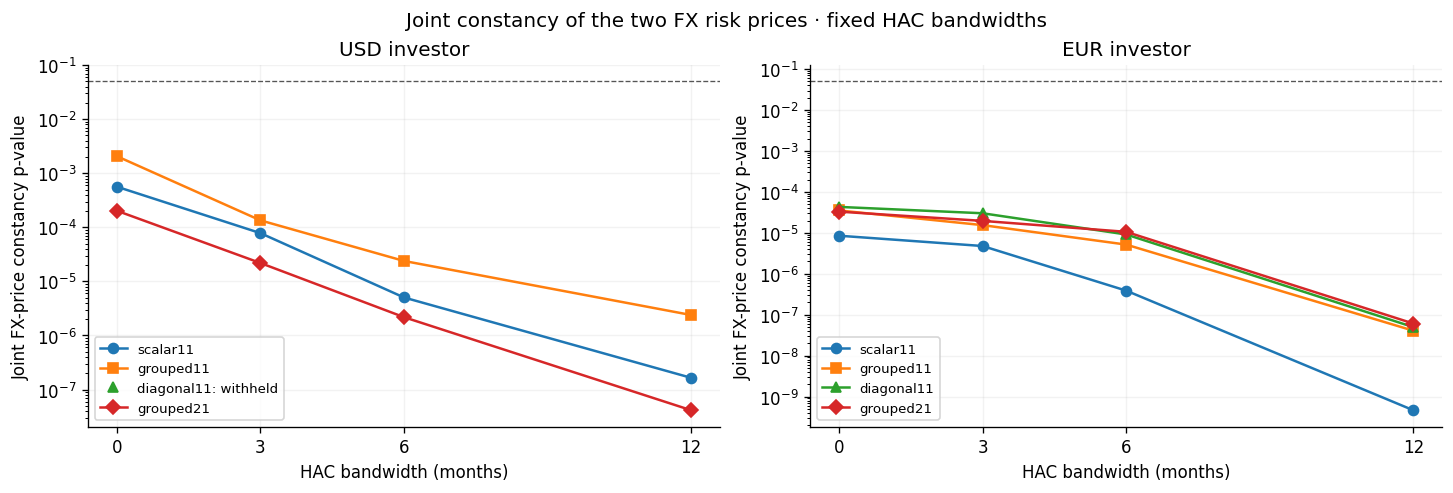

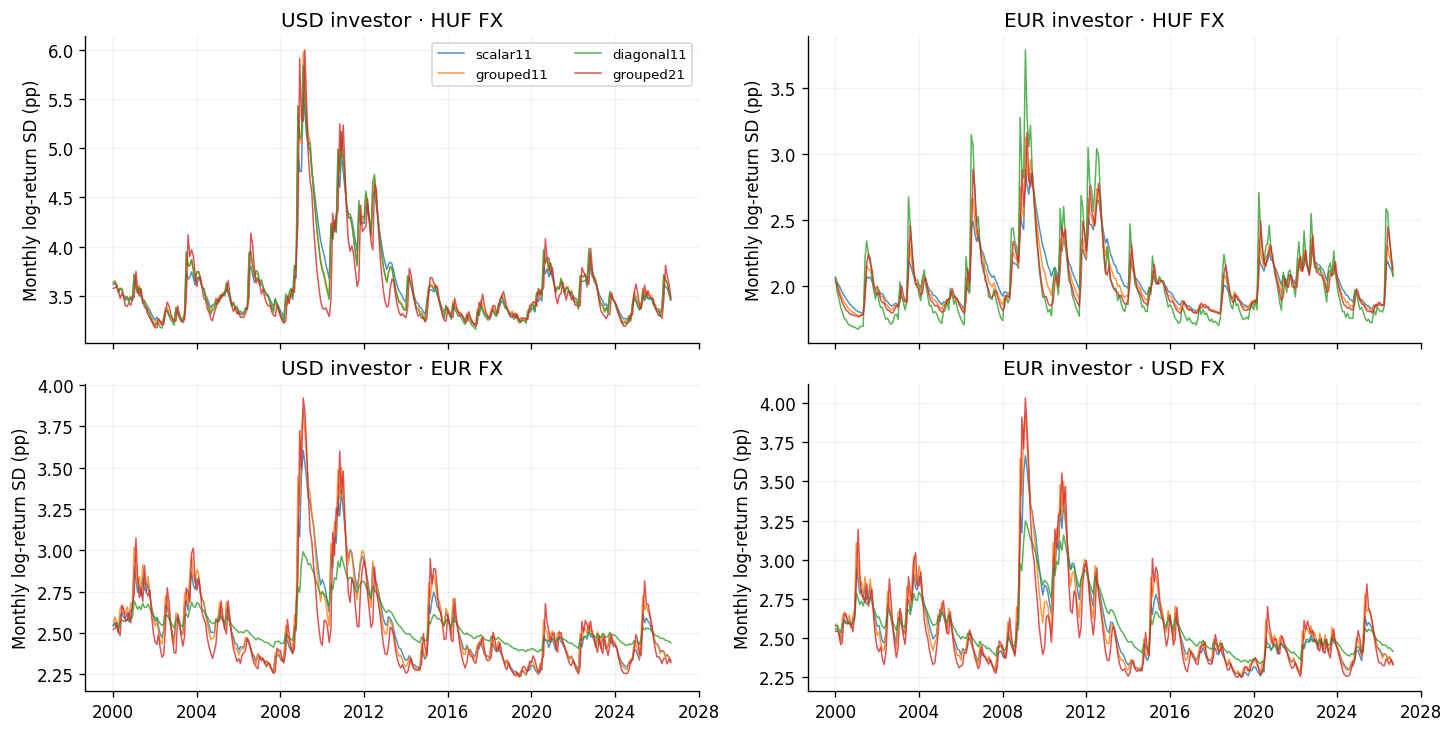

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
markers=["o","s","^","D"]
for ax,currency in zip(axes,["USD","EUR"]):
    for name,marker in zip(MODELS,markers):
        key=f"{currency}_{name}"
        rows=tests.xs((key,"FX prices constant"),level=("case","test")).reindex(HAC_LAGS)
        if rows["robust_p_value"].notna().any():ax.plot(HAC_LAGS,rows["robust_p_value"],marker=marker,label=name)
        else:ax.plot([],[],marker=marker,linestyle="none",label=f"{name}: withheld")
    ax.axhline(.05,color="#555555",lw=.8,ls="--")
    ax.set(title=f"{currency} investor",xlabel="HAC bandwidth (months)",ylabel="Joint FX-price constancy p-value",xticks=HAC_LAGS)
    ax.set_yscale("log");ax.legend(fontsize=8)
fig.suptitle("Joint constancy of the two FX risk prices · fixed HAC bandwidths")
plt.savefig(OUT/"01_FX_constancy_HAC.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()
fig,axes=plt.subplots(2,2,figsize=(12,6),sharex=True,layout="constrained")
for col,currency in enumerate(["USD","EUR"]):
    for row,position in enumerate([3,4]):
        for name in MODELS:
            case=fits[f"{currency}_{name}"]
            axes[row,col].plot(data.index.to_timestamp(),np.sqrt(case["filter"]["H"][:,position,position]),label=name,lw=.9,alpha=.8)
        other="EUR" if currency=="USD" else "USD"
        axes[row,col].set(title=f"{currency} investor · {('HUF' if row==0 else other)} FX",ylabel="Monthly log-return SD (pp)")
axes[0,0].legend(ncol=2,fontsize=8)
plt.savefig(OUT/"02_FX_volatility.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

## 5. Save the audit and state what remains

Exports include fit attempts, point estimates, score-HAC uncertainty, nominal/adjusted diagnostics,
fitted covariance/mean paths and Hungary's fitted premium components. The latter are **conditional
model means**, not forecasts evaluated out of sample or realized returns. All components sum to the
Hungarian mean. Retain failed specification/identification checks in the research record.

In [6]:
tables={"model_comparison.csv":summary,"restriction_tests.csv":tests,"price_coefficients.csv":coefficients,
        "residual_diagnostics.csv":residuals,"cross_covariance_diagnostics.csv":cross_diagnostics,"score_diagnostics.csv":score_diagnostics,
        "starting_points.csv":starting_points}
for name,table in tables.items():table.to_csv(OUT/name)
for key,case in fits.items():
    f,inf=case["filter"],case["inference"]
    covariance_arrays={f"covariance_HAC{h}":v["covariance"] for h,v in inf["estimates"].items()}
    np.savez_compressed(OUT/f"parameters_{key}.npz",theta=case["theta"],H=f["H"],mu=f["mu"],residuals=f["errors"],scores=f["scores"],Hessian=inf["Hessian"],**covariance_arrays)
    premia=pd.DataFrame({"world":f["world_prices"]*f["H"][:,2,0],"HUF_FX":f["fx_prices"][:,0]*f["H"][:,2,3],
                         "other_FX":f["fx_prices"][:,1]*f["H"][:,2,4],"local":f["prices"][2]*f["H"][:,2,2]},index=data.index)
    np.testing.assert_allclose(premia.sum(axis=1),f["mu"][:,2],atol=1e-11,rtol=1e-11)
    premia["total"]=f["mu"][:,2];premia.to_csv(OUT/f"premia_{key}.csv")
record={"model_version":MODEL_VERSION,"snapshot":SNAPSHOT,"source_dataset_sha256":manifest["exports"]["dataset.csv"],
        "first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),"mean_model":"paper-style FX means; local prices constant",
        "models":MODELS,"HAC_lags":HAC_LAGS,"diagnostic_lags":TEST_LAGS,"SE_step_tolerance":SE_STEP_TOL,
        "engines":engine_hashes,"upstream":UPSTREAM,"upstream_file_sha256":upstream_hashes,"conditioning_file_sha256":prior["upstream_file_sha256"],
        "instrument_specification":prior["instrument_specification"],"python":platform.python_version(),"packages":versions}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
display(Markdown("**Final comparison — all estimates and diagnostics retained**"))
display(summary[["n","parameters","AIC_from_best","BIC_from_best","sandwich_ready_all_lags","variance_flags","variance_flags_holm","cross_flags"]].round(4))
display(tests.xs("FX prices constant",level="test")["robust_p_value"].unstack("HAC_lags"))
for currency in ["USD","EUR"]:
    rows=summary[summary["perspective"].eq(currency)]
    best=rows["AIC"].idxmin();bic_best=rows["BIC"].idxmin()
    p=tests.xs((best,"FX prices constant"),level=("case","test"))["robust_p_value"].dropna()
    span=f"{p.min():.4g} to {p.max():.4g}" if len(p) else "withheld"
    display(Markdown(f"**{currency}:** lowest descriptive AIC is `{best}`; lowest BIC is `{bic_best}`. "
                     f"The AIC winner has BIC **{rows.loc[best,'BIC']-rows.loc[bic_best,'BIC']:.2f}** above the BIC winner. "
                     f"Joint FX constancy p-values across the fixed bandwidths for the AIC winner: **{span}**. "
                     f"Nominal variance flags: **{int(rows.loc[best,'variance_flags'])}**; Holm-adjusted variance flags: **{int(rows.loc[best,'variance_flags_holm'])}**. "
                     "These are conditional specification-sensitivity results."))
display(Markdown("HAC changes uncertainty only. Remaining residual failures or identification problems remain unresolved; "
    "a clean adjusted screen alone does not establish correct specification. Retain the scalar benchmark and the grouped two-shock-lag sensitivity "
    "when extending local-risk pricing, rather than selecting a specification by significance. "
    "Time-varying Hungarian local risk and pricing-error intercept tests are still to come. "
    f"Outputs: `{OUT.relative_to(ROOT)}`."))

**Final comparison — all estimates and diagnostics retained**

,n,parameters,AIC_from_best,BIC_from_best,sandwich_ready_all_lags,variance_flags,variance_flags_holm,cross_flags
case,,,,,,,,
USD_scalar11,321,34,1.9192,0.0000,True,4,1,0
USD_grouped11,321,38,5.3084,18.4750,True,2,1,0
USD_diagonal11,321,42,6.0648,34.3171,False,2,1,1
USD_grouped21,321,41,0.0000,24.4809,True,1,0,0
EUR_scalar11,321,34,1.8487,0.0000,True,1,1,0
EUR_grouped11,321,38,3.8561,17.0931,True,1,0,0
EUR_diagonal11,321,42,6.9908,35.3136,True,1,1,0
EUR_grouped21,321,41,0.0000,24.5514,True,0,0,0


HAC_lags,0,3,6,12
case,,,,
EUR_diagonal11,0.000043,0.000030,9.121983e-06,4.973601e-08
EUR_grouped11,0.000035,0.000015,5.160440e-06,4.069183e-08
EUR_grouped21,0.000033,0.000020,1.057925e-05,6.085551e-08
EUR_scalar11,0.000009,0.000005,3.871002e-07,4.630553e-10
USD_diagonal11,NaN,NaN,NaN,NaN
USD_grouped11,0.002071,0.000135,2.388717e-05,2.389832e-06
USD_grouped21,0.000203,0.000022,2.180249e-06,4.137828e-08
USD_scalar11,0.000565,0.000078,5.043392e-06,1.646326e-07


**USD:** lowest descriptive AIC is `USD_grouped21`; lowest BIC is `USD_scalar11`. The AIC winner has BIC **24.48** above the BIC winner. Joint FX constancy p-values across the fixed bandwidths for the AIC winner: **4.138e-08 to 0.0002028**. Nominal variance flags: **1**; Holm-adjusted variance flags: **0**. These are conditional specification-sensitivity results.

**EUR:** lowest descriptive AIC is `EUR_grouped21`; lowest BIC is `EUR_scalar11`. The AIC winner has BIC **24.55** above the BIC winner. Joint FX constancy p-values across the fixed bandwidths for the AIC winner: **6.086e-08 to 3.296e-05**. Nominal variance flags: **0**; Holm-adjusted variance flags: **0**. These are conditional specification-sensitivity results.

HAC changes uncertainty only. Remaining residual failures or identification problems remain unresolved; a clean adjusted screen alone does not establish correct specification. Retain the scalar benchmark and the grouped two-shock-lag sensitivity when extending local-risk pricing, rather than selecting a specification by significance. Time-varying Hungarian local risk and pricing-error intercept tests are still to come. Outputs: `output/09_covariance_robustness/fixed_2026-11-13/2000-01_2026-09/paper_fx_means`.